<a href="https://colab.research.google.com/github/Raksha354/raksharepo/blob/main/ML_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting YouTube Video Engagement Levels from Metadata and Channel Characteristics

# **Team** **Members** **:- Shreyansh Jain ,** **Raksha H B ,** **Deepika**

**ES514 course project - Google Colab notebook**

**Research question:** Can video metadata and channel characteristics predict YouTube engagement levels (Low / Medium / High) *without* using direct engagement counts as model inputs?

Engagement rate (%) = likeCount / viewCount x 100. Models: Logistic Regression, Decision Tree, Random Forest.


## Cell 1 - Setup
We import the libraries, fix the random seed, and make sure the CSV is available. In Colab, if `data.csv` is not found, a file-upload box appears.

In [ ]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GroupShuffleSplit, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [ ]:
df = pd.read_csv("/content/data (1).csv")
print("Dataset loaded successfully")
print(df.shape)
print(df.head())

Dataset loaded successfully
(315334, 36)
   Unnamed: 0         V_id  caption  categoryId                 channelId  \
0           0  JxCqMLJbRnE        0           0  UCJRYoVWkItEvCK5LZn2tppQ   
1           1  ZFoWiUqrhoE        0           0  UCTCjFFoX1un-j7ni4B6HJ3Q   
2           2  BzXutu_iVoA        0           0  UC9k-yiEpRHMNVOnOi_aQK8w   
3           3  YGenu4ZFnmQ        0           0  UC3gNmTGu-TTbFPpfSs5kNkg   
4           4  i9DsO2dsZX8        0           0  UCtDiNBH4ESgnM5IbAJXtmTA   

   commentCount defaultAudioLanguage  definition  dimension  dislikeCount  \
0         249.0                  NaN           0          0          25.0   
1          17.0                  NaN           0          0           5.0   
2         971.0                  NaN           0          0         263.0   
3           2.0                  NaN           0          0           4.0   
4           2.0                  NaN           0          0           4.0   

   duration  embeddable  licenced

## Cell 2 - Data audit (before any modelling)
We look at size, column names, data types, missing values, duplicates, and invalid values. We also **check that every column we plan to use really exists** (the `assert` stops the notebook with a clear message if not).

In [ ]:
df_raw = pd.read_csv("/content/data (1).csv")
print("Rows, columns:", df_raw.shape)
display(df_raw.head(3))
display(df_raw.dtypes.to_frame("dtype").T)

miss = df_raw.isna().sum()
print("\nColumns with missing values:")
display(miss[miss > 0].to_frame("n_missing").assign(pct=lambda d: (100 * d.n_missing / len(df_raw)).round(1)))

required = ["V_id", "channelId", "categoryId", "likeCount", "viewCount", "commentCount", "dislikeCount",
            "duration", "video_title_length", "description_length", "No_of_tags", "tags_in_title",
            "tags_in_desc", "http_in_descp", "day_uploaded", "months_old", "channel_months_old",
            "channel_subscriberCount", "channel_ViewCount", "channel_videoCount", "channel_commentCount",
            "channel_title_length", "channel_description_length", "social_links", "twitter_url",
            "defaultAudioLanguage", "caption", "definition", "dimension", "embeddable",
            "licencedContent", "license", "privacyStatus", "projection"]
absent = [c for c in required if c not in df_raw.columns]
assert not absent, f"Columns not found in the CSV: {absent}"

count_cols = ["likeCount", "viewCount", "commentCount", "dislikeCount"]
audit = pd.Series({
    "duplicate rows (ignoring index column)": int(df_raw.drop(columns="Unnamed: 0").duplicated().sum()),
    "duplicate video IDs (V_id)": int(df_raw["V_id"].duplicated().sum()),
    "negative counts": int((df_raw[count_cols] < 0).sum().sum()),
    "videos with zero views": int((df_raw["viewCount"] == 0).sum()),
    "videos with zero likes": int((df_raw["likeCount"] == 0).sum()),
    "likes greater than views": int((df_raw["likeCount"] > df_raw["viewCount"]).sum()),
    "zero duration": int((df_raw["duration"] == 0).sum()),
    "channels with zero subscribers": int((df_raw["channel_subscriberCount"] == 0).sum()),
    "tags_in_title identical to tags_in_desc (share of rows)": float((df_raw["tags_in_title"] == df_raw["tags_in_desc"]).mean()),
    "number of distinct channels": int(df_raw["channelId"].nunique()),
    "videos from the single biggest channel": int(df_raw["channelId"].value_counts().iloc[0]),
})
display(audit.to_frame("value"))

Rows, columns: (347623, 36)


,Unnamed: 0,V_id,caption,categoryId,channelId,commentCount,defaultAudioLanguage,definition,dimension,dislikeCount,duration,embeddable,licencedContent,license,likeCount,privacyStatus,projection,thumbnail,viewCount,channel_ViewCount,channel_commentCount,channel_subscriberCount,channel_videoCount,description_length,http_in_descp,tags_in_desc,video_title_length,tags_in_title,No_of_tags,channel_title_length,channel_description_length,months_old,channel_months_old,day_uploaded,social_links,twitter_url
0,0,JxCqMLJbRnE,0,0,UCJRYoVWkItEvCK5LZn2tppQ,249.0,NaN,0,0,25.0,218.0,1,0,1,780.0,0,1,https://i.ytimg.com/vi/JxCqMLJbRnE/mqdefault.jpg,370016,14799752,0,12457,90,184,1,26,8,26,29,1,37,53,57.0,1,5,https://twitter.com/thesnoutypig
1,1,ZFoWiUqrhoE,0,0,UCTCjFFoX1un-j7ni4B6HJ3Q,17.0,NaN,0,0,5.0,138.0,1,1,1,148.0,0,1,https://i.ytimg.com/vi/ZFoWiUqrhoE/mqdefault.jpg,46535,368731647,21,183151,3261,126,5,12,13,12,29,3,58,26,62.0,4,9,http://twitter.com/movieclips/
2,2,BzXutu_iVoA,0,0,UC9k-yiEpRHMNVOnOi_aQK8w,971.0,NaN,0,0,263.0,148.0,1,1,1,11804.0,0,1,https://i.ytimg.com/vi/BzXutu_iVoA/mqdefault.jpg,2575951,1050069059,0,726214,7262,85,0,2,13,2,3,2,10,12,51.0,5,5,https://twitter.com/insideedition


,Unnamed: 0,V_id,caption,categoryId,channelId,commentCount,defaultAudioLanguage,definition,dimension,dislikeCount,duration,embeddable,licencedContent,license,likeCount,privacyStatus,projection,thumbnail,viewCount,channel_ViewCount,channel_commentCount,channel_subscriberCount,channel_videoCount,description_length,http_in_descp,tags_in_desc,video_title_length,tags_in_title,No_of_tags,channel_title_length,channel_description_length,months_old,channel_months_old,day_uploaded,social_links,twitter_url
dtype,int64,object,int64,int64,object,float64,object,int64,int64,float64,float64,int64,int64,int64,float64,int64,int64,object,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,int64,int64,object



Columns with missing values:


,n_missing,pct
defaultAudioLanguage,284405,81.8
twitter_url,126005,36.2


,value
duplicate rows (ignoring index column),0.0
duplicate video IDs (V_id),1.0
negative counts,0.0
videos with zero views,3.0
videos with zero likes,1680.0
likes greater than views,3.0
zero duration,38.0
channels with zero subscribers,3795.0
tags_in_title identical to tags_in_desc (share of rows),1.0
number of distinct channels,96537.0


In [ ]:
# Keep the raw columns available for EDA. Cleaning and target creation happen once in Cell 9.
df = df_raw.copy()
print("Raw working copy:", df.shape)
display(df.head())


Raw working copy: (347623, 36)


,Unnamed: 0,V_id,caption,categoryId,channelId,commentCount,defaultAudioLanguage,definition,dimension,dislikeCount,duration,embeddable,licencedContent,license,likeCount,privacyStatus,projection,thumbnail,viewCount,channel_ViewCount,channel_commentCount,channel_subscriberCount,channel_videoCount,description_length,http_in_descp,tags_in_desc,video_title_length,tags_in_title,No_of_tags,channel_title_length,channel_description_length,months_old,channel_months_old,day_uploaded,social_links,twitter_url
0,0,JxCqMLJbRnE,0,0,UCJRYoVWkItEvCK5LZn2tppQ,249.0,NaN,0,0,25.0,218.0,1,0,1,780.0,0,1,https://i.ytimg.com/vi/JxCqMLJbRnE/mqdefault.jpg,370016,14799752,0,12457,90,184,1,26,8,26,29,1,37,53,57.0,1,5,https://twitter.com/thesnoutypig
1,1,ZFoWiUqrhoE,0,0,UCTCjFFoX1un-j7ni4B6HJ3Q,17.0,NaN,0,0,5.0,138.0,1,1,1,148.0,0,1,https://i.ytimg.com/vi/ZFoWiUqrhoE/mqdefault.jpg,46535,368731647,21,183151,3261,126,5,12,13,12,29,3,58,26,62.0,4,9,http://twitter.com/movieclips/
2,2,BzXutu_iVoA,0,0,UC9k-yiEpRHMNVOnOi_aQK8w,971.0,NaN,0,0,263.0,148.0,1,1,1,11804.0,0,1,https://i.ytimg.com/vi/BzXutu_iVoA/mqdefault.jpg,2575951,1050069059,0,726214,7262,85,0,2,13,2,3,2,10,12,51.0,5,5,https://twitter.com/insideedition
3,3,YGenu4ZFnmQ,0,0,UC3gNmTGu-TTbFPpfSs5kNkg,2.0,NaN,0,0,4.0,245.0,1,1,1,85.0,0,1,https://i.ytimg.com/vi/YGenu4ZFnmQ/mqdefault.jpg,43341,5383943661,1546,4181230,24504,152,18,1,13,1,10,1,80,35,129.0,0,9,https://twitter.com/MOVIECLIPS
4,4,i9DsO2dsZX8,0,0,UCtDiNBH4ESgnM5IbAJXtmTA,2.0,NaN,0,0,4.0,876.0,1,0,1,26.0,0,1,https://i.ytimg.com/vi/i9DsO2dsZX8/mqdefault.jpg,3280,16132,0,9,91,71,0,3,8,3,6,2,1,8,18.0,2,0,NaN


## Cell 3 - Cleaning and creating the target

In [ ]:
# Canonical cleaning and target creation: this is the single source of truth for later cells.
df = df_raw.copy()

# Drop only the exported dataframe index, if present.
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
n_start = len(df)

# Keep one record per video.
df = df.drop_duplicates(subset="V_id", keep="first").copy()
n_after_dups = len(df)

# Convert count columns to numeric safely.
for col in ["likeCount", "viewCount", "commentCount", "dislikeCount"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove invalid/undefined engagement rows.
df = df[df["viewCount"].gt(0)]
n_after_zero_views = len(df)
df = df[df["likeCount"].ge(0) & df["viewCount"].ge(0) & df["likeCount"].le(df["viewCount"])].copy()
df = df.reset_index(drop=True)

print(f"Start: {n_start:,}; after duplicate IDs: {n_after_dups:,}; after zero views: {n_after_zero_views:,}; final: {len(df):,}")

df["engagement_rate"] = (df["likeCount"] / df["viewCount"]) * 100

# Quantile labels: rank first so ties at tercile boundaries cannot create NaN labels.
# Note: equal engagement rates can fall in different classes when a boundary cuts through ties.
ranks = df["engagement_rate"].rank(method="first")
df["engagement_level"] = pd.qcut(
    ranks, q=3, labels=["Low", "Medium", "High"]
)

print("Tercile cut-offs (approximate):", df["engagement_rate"].quantile([1/3, 2/3]).round(3).to_dict())
print("Missing target labels:", int(df["engagement_level"].isna().sum()))
display(df["engagement_level"].value_counts().reindex(["Low", "Medium", "High"]).to_frame("count").assign(
    pct=lambda x: (100 * x["count"] / len(df)).round(1)
))
display(df["engagement_rate"].describe(percentiles=[.01, .25, .5, .75, .99]).to_frame("engagement_rate (%)").T)


Start: 347,623; after duplicate IDs: 347,622; after zero views: 347,619; final: 347,616
Tercile cut-offs (approximate): {0.3333333333333333: 0.405, 0.6666666666666666: 0.945}
Missing target labels: 0


,count,pct
engagement_level,,
Low,115872,33.3
Medium,115872,33.3
High,115872,33.3


,count,mean,std,min,1%,25%,50%,75%,99%,max
engagement_rate (%),347616.0,1.009584,1.214791,0.0,0.056947,0.326024,0.606918,1.221374,5.848417,57.692308


## Cell 4 - EDA

Text(0.5, 1.0, 'Engagement Level Distribution')

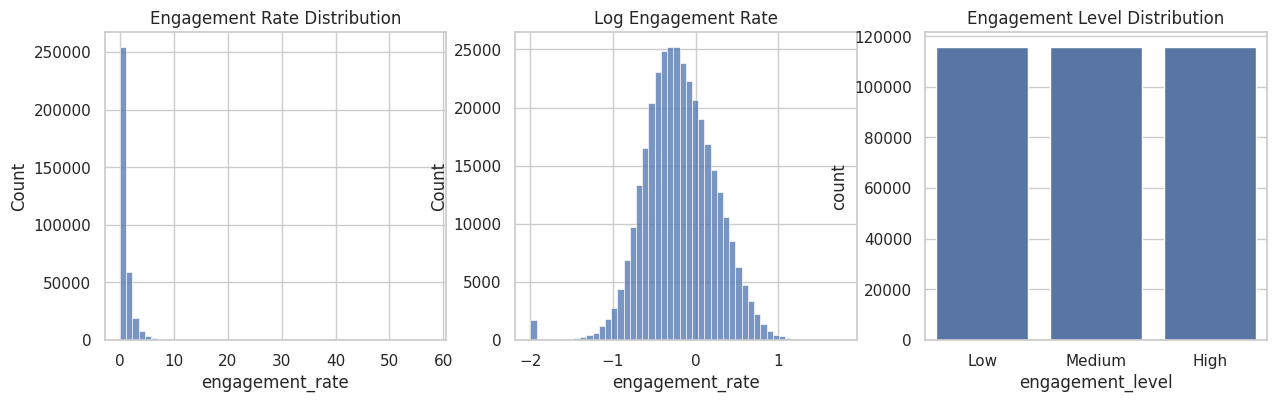

In [ ]:
from google.colab import files
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(df["engagement_rate"], bins=50)
plt.title("Engagement Rate Distribution")

plt.subplot(1, 3, 2)
sns.histplot(np.log10(df["engagement_rate"] + 0.01), bins=50)
plt.title("Log Engagement Rate")

plt.subplot(1, 3, 3)
sns.countplot(x="engagement_level", data=df)
plt.title("Engagement Level Distribution")



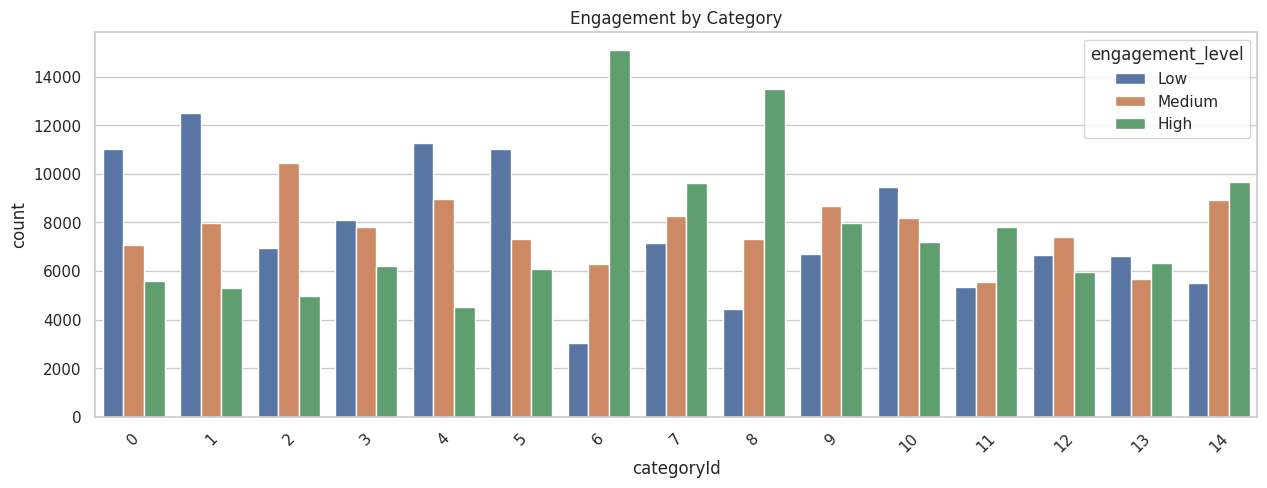

In [ ]:
plt.figure(figsize=(15, 5))
sns.countplot(x="categoryId", hue="engagement_level", data=df)
plt.title("Engagement by Category")
plt.xticks(rotation=45)
plt.show()

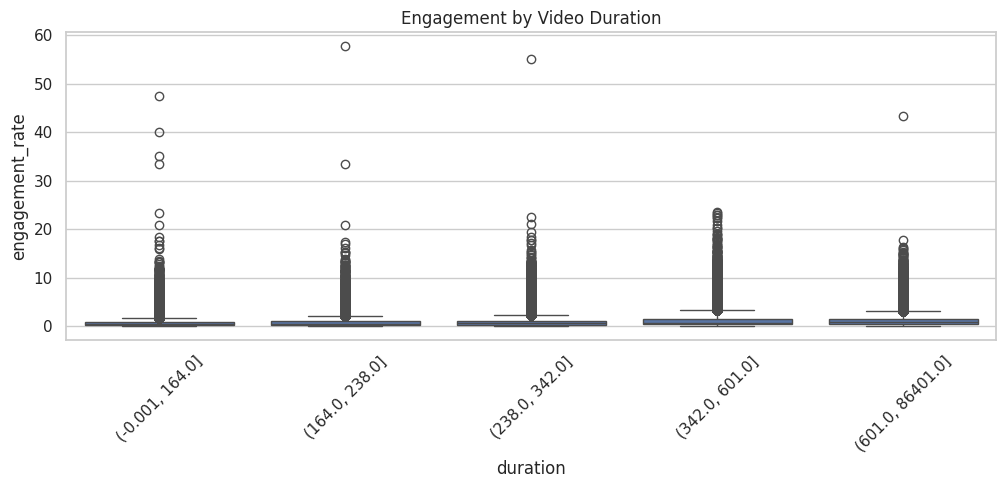

In [ ]:
plt.figure(figsize=(12, 4))

sns.boxplot(x=pd.qcut(df["duration"], 5, duplicates="drop"), y="engagement_rate", data=df)
plt.title("Engagement by Video Duration")
plt.xticks(rotation=45)
plt.show()

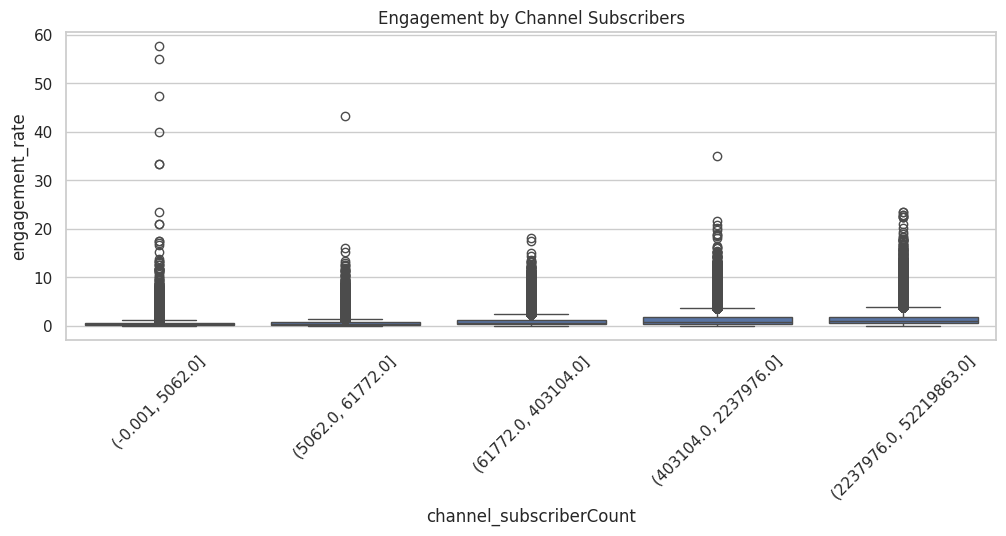

In [ ]:
plt.figure(figsize=(12, 4))
sns.boxplot(x=pd.qcut(df["channel_subscriberCount"], 5, duplicates="drop"), y="engagement_rate", data=df)
plt.title("Engagement by Channel Subscribers")
plt.xticks(rotation=45)
plt.show()

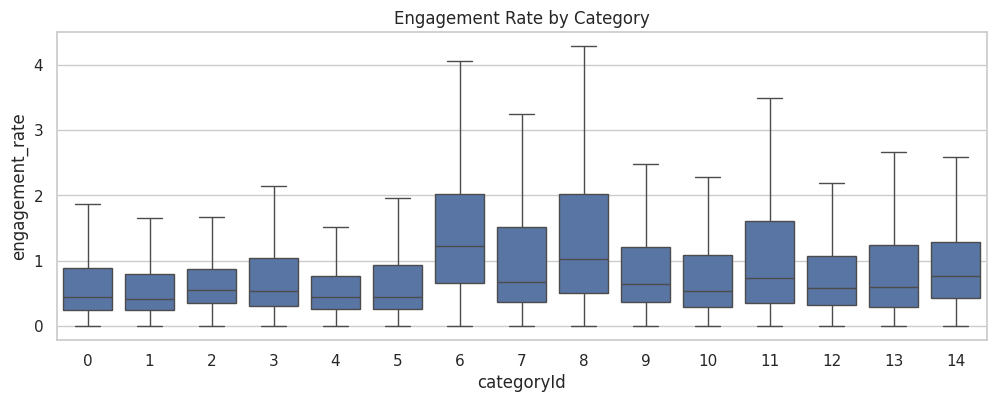

In [ ]:
plt.figure(figsize=(12, 4))
sns.boxplot(x="categoryId", y="engagement_rate", data=df, showfliers=False)
plt.title("Engagement Rate by Category")
plt.show()


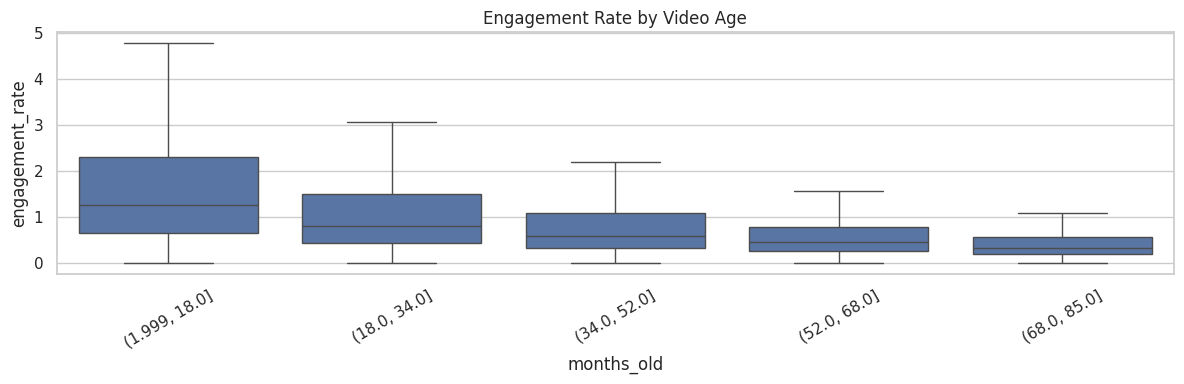

In [ ]:
plt.figure(figsize=(12, 4))
sns.boxplot(x=pd.qcut(df["months_old"], 5, duplicates="drop"), y="engagement_rate", data=df, showfliers=False)
plt.title("Engagement Rate by Video Age")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Cell 5 - EDA part 3: correlations, missing values and outliers in the inputs
Spearman correlation is used because it works with skewed data. Correlation with the *target rate* here is for exploration only. We also list missing values and the share of IQR-outliers in the main numeric columns.

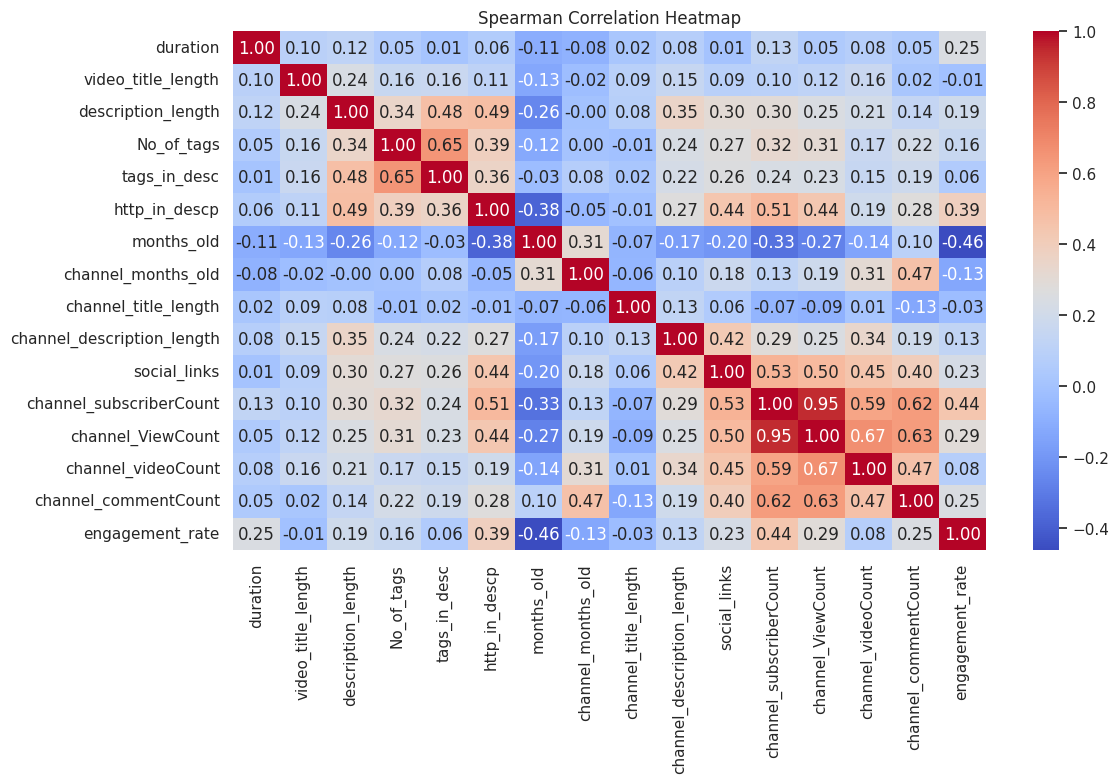

Correlation with Engagement Rate:


,engagement_rate
engagement_rate,1.000000
channel_subscriberCount,0.442374
http_in_descp,0.387656
channel_ViewCount,0.290709
duration,0.251169
channel_commentCount,0.247521
social_links,0.225656
description_length,0.190511
No_of_tags,0.159756
channel_description_length,0.129698


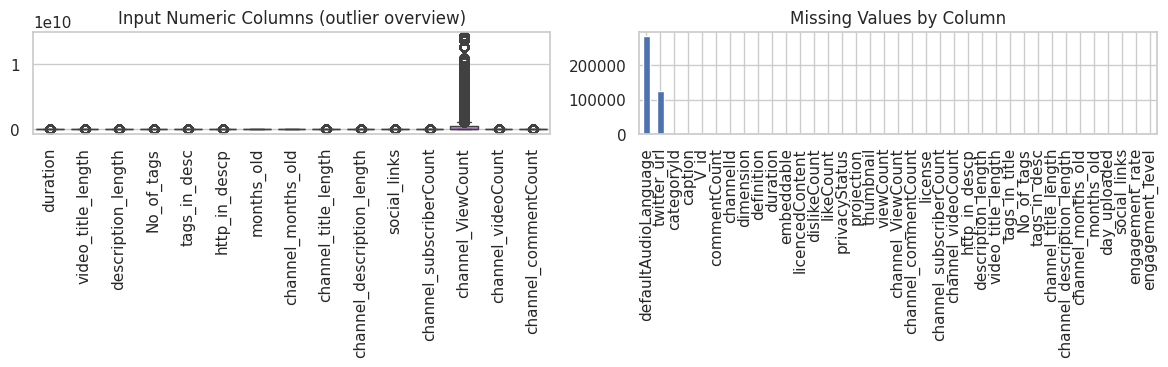

In [ ]:
# Correlation / missingness EDA. Only use columns that actually exist.
cols_requested = ["duration", "video_title_length", "description_length", "No_of_tags",
        "tags_in_desc", "http_in_descp", "months_old", "channel_months_old",
        "channel_title_length", "channel_description_length", "social_links",
        "channel_subscriberCount", "channel_ViewCount", "channel_videoCount",
        "channel_commentCount", "engagement_rate"]
cols = [c for c in cols_requested if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]
if len(cols) >= 2:
    corr = df[cols].corr(method="spearman")
    plt.figure(figsize=(12, 8))
    sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Spearman Correlation Heatmap")
    plt.tight_layout()
    plt.show()
    if "engagement_rate" in corr.columns:
        print("Correlation with Engagement Rate:")
        display(corr["engagement_rate"].sort_values(ascending=False))

numeric_cols = [c for c in cols if c != "engagement_rate"]
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
if numeric_cols:
    sns.boxplot(data=df[numeric_cols])
    plt.xticks(rotation=90)
plt.title("Input Numeric Columns (outlier overview)")
plt.subplot(1, 2, 2)
df.isnull().sum().sort_values(ascending=False).plot(kind="bar")
plt.title("Missing Values by Column")
plt.tight_layout()
plt.show()


Outliers Before Handling: 58550


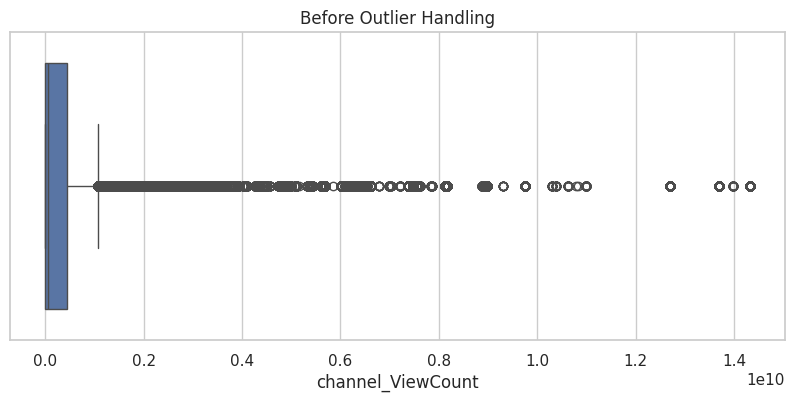

Outliers After Handling: 1428


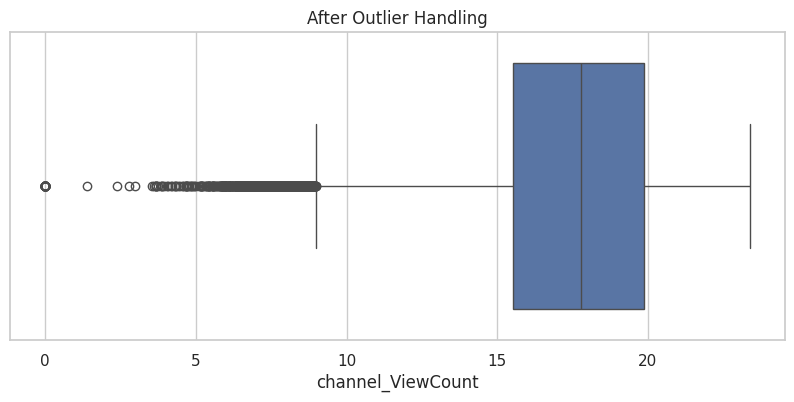

In [ ]:
# Inspect channel_ViewCount outliers. Do not mutate the feature here; log transform is
# applied inside the model pipeline to avoid double-transforming and train/test leakage


# Handle Outliers in channel_ViewCount

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Check outliers before handling
Q1 = df["channel_ViewCount"].quantile(0.25)
Q3 = df["channel_ViewCount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = ((df["channel_ViewCount"] < lower) |
            (df["channel_ViewCount"] > upper)).sum()

print("Outliers Before Handling:", outliers)

# Plot before handling
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["channel_ViewCount"])
plt.title("Before Outlier Handling")
plt.show()

# Handle large values using log transformation
df["channel_ViewCount"] = np.log1p(df["channel_ViewCount"])

# Check outliers after handling
Q1 = df["channel_ViewCount"].quantile(0.25)
Q3 = df["channel_ViewCount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = ((df["channel_ViewCount"] < lower) |
            (df["channel_ViewCount"] > upper)).sum()

print("Outliers After Handling:", outliers)

# Plot after handling
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["channel_ViewCount"])
plt.title("After Outlier Handling")
plt.show()


We don't Use twitter_url and DefaultAudioLanguage so we are dropping this

Cleaned dataframe shape: (347616, 36)


,V_id,caption,categoryId,channelId,commentCount,definition,dimension,dislikeCount,duration,embeddable,licencedContent,license,likeCount,privacyStatus,projection,viewCount,channel_ViewCount,channel_commentCount,channel_subscriberCount,channel_videoCount,description_length,http_in_descp,tags_in_desc,video_title_length,tags_in_title,No_of_tags,channel_title_length,channel_description_length,months_old,channel_months_old,day_uploaded,social_links,engagement_rate,engagement_level,has_twitter_url,has_audio_language
0,JxCqMLJbRnE,0,0,UCJRYoVWkItEvCK5LZn2tppQ,249.0,0,0,25.0,218.0,1,0,1,780.0,0,1,370016,16.510121,0,12457,90,184,1,26,8,26,29,1,37,53,57.0,1,5,0.210802,Low,1,0
1,ZFoWiUqrhoE,0,0,UCTCjFFoX1un-j7ni4B6HJ3Q,17.0,0,0,5.0,138.0,1,1,1,148.0,0,1,46535,19.725580,21,183151,3261,126,5,12,13,12,29,3,58,26,62.0,4,9,0.318040,Low,1,0
2,BzXutu_iVoA,0,0,UC9k-yiEpRHMNVOnOi_aQK8w,971.0,0,0,263.0,148.0,1,1,1,11804.0,0,1,2575951,20.772122,0,726214,7262,85,0,2,13,2,3,2,10,12,51.0,5,5,0.458239,Medium,1,0
3,YGenu4ZFnmQ,0,0,UC3gNmTGu-TTbFPpfSs5kNkg,2.0,0,0,4.0,245.0,1,1,1,85.0,0,1,43341,22.406687,1546,4181230,24504,152,18,1,13,1,10,1,80,35,129.0,0,9,0.196119,Low,1,0
4,i9DsO2dsZX8,0,0,UCtDiNBH4ESgnM5IbAJXtmTA,2.0,0,0,4.0,876.0,1,0,1,26.0,0,1,3280,9.688622,0,9,91,71,0,3,8,3,6,2,1,8,18.0,2,0,0.792683,Medium,0,0


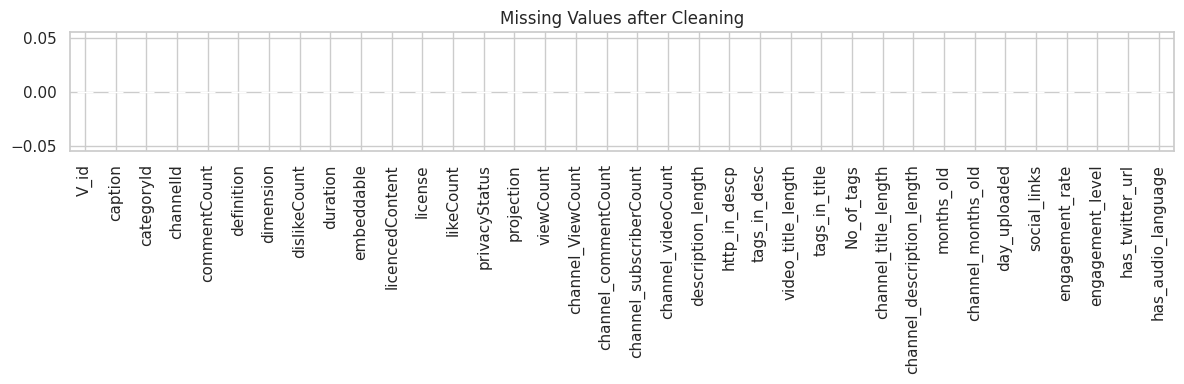

In [ ]:

for col in ["twitter_url", "defaultAudioLanguage"]:
    if col not in df.columns:
        df[col] = np.nan

df["has_twitter_url"] = df["twitter_url"].notna().astype("int8")
df["has_audio_language"] = df["defaultAudioLanguage"].notna().astype("int8")

# Drop raw text/identifier columns that are not intended as model inputs.
df = df.drop(columns=["thumbnail", "twitter_url", "defaultAudioLanguage"], errors="ignore")
print("Cleaned dataframe shape:", df.shape)
display(df.head())
df.isnull().sum().sort_values(ascending=False).plot(kind="bar", figsize=(12, 4))
plt.title("Missing Values after Cleaning")
plt.tight_layout()
plt.show()


## Cell 6- Leakage check and feature selection
**Excluded from model inputs:** `likeCount`, `viewCount`, `commentCount`, `dislikeCount`, `engagement_rate`, `engagement_level` (target-defining information), plus identifiers/free text such as `V_id`, `channelId`, `thumbnail`, `twitter_url`. `tags_in_title` is excluded because the audit indicated it duplicates `tags_in_desc`.

**Four feature sets for ablation:**
- **A - All allowed features**
- **B - A without channel popularity counts** (`channel_subscriberCount`, `channel_ViewCount`, `channel_videoCount`, `channel_commentCount`)
- **C - Video-only features** (removes all columns starting with `channel_` from B)
- **D - B without `months_old`**

The model is trained and evaluated for all four sets using the same stratified train/test rows. This is a metadata-snapshot classification task, not a claim of prediction at upload time.


df_removed is the dataframe which have "likeCount", "viewCount", "commentCount", "dislikeCount","engagement_rate", "V_id", "channelId", "thumbnail", "tags_in_title" these featers

In [ ]:
# Keep target-defining counts and identifiers separately for post-model error analysis only.
error_cols = [c for c in ["likeCount", "viewCount", "commentCount", "dislikeCount",
                          "engagement_rate", "engagement_level", "V_id", "channelId", "tags_in_title"]
              if c in df.columns]
df_removed = df[error_cols].copy()
display(df_removed.head())
print("Post-analysis reference table shape:", df_removed.shape)


,likeCount,viewCount,commentCount,dislikeCount,engagement_rate,engagement_level,V_id,channelId,tags_in_title
0,780.0,370016,249.0,25.0,0.210802,Low,JxCqMLJbRnE,UCJRYoVWkItEvCK5LZn2tppQ,26
1,148.0,46535,17.0,5.0,0.318040,Low,ZFoWiUqrhoE,UCTCjFFoX1un-j7ni4B6HJ3Q,12
2,11804.0,2575951,971.0,263.0,0.458239,Medium,BzXutu_iVoA,UC9k-yiEpRHMNVOnOi_aQK8w,2
3,85.0,43341,2.0,4.0,0.196119,Low,YGenu4ZFnmQ,UC3gNmTGu-TTbFPpfSs5kNkg,1
4,26.0,3280,2.0,4.0,0.792683,Medium,i9DsO2dsZX8,UCtDiNBH4ESgnM5IbAJXtmTA,3


Post-analysis reference table shape: (347616, 9)


In [ ]:
# Build feature lists without deleting columns from df, so target/error-analysis data remain available.
excluded_from_X = [
    "likeCount", "viewCount", "commentCount", "dislikeCount",
    "engagement_rate", "engagement_level", "V_id", "channelId", "thumbnail",
    "tags_in_title"
]
features_A = [c for c in df.columns if c not in excluded_from_X]

# Do not allow raw date/time-like identifiers or object free text to enter accidentally.
# Keep intended categorical columns and numeric metadata only.
features_B = [c for c in features_A if c not in [
    "channel_subscriberCount", "channel_ViewCount", "channel_videoCount", "channel_commentCount"
]]
features_C = [c for c in features_B if not c.startswith("channel_")]
features_D = [c for c in features_B if c != "months_old"]

print("A - All allowed features:", len(features_A))
print("B - Without channel popularity counts:", len(features_B))
print("C - Video-only features:", len(features_C))
print("D - B without video age:", len(features_D))
print("Target available:", "engagement_level" in df.columns)
print("Potential object columns in A:", df[features_A].select_dtypes(include="object").columns.tolist())


A - All allowed features: 27
B - Without channel popularity counts: 23
C - Video-only features: 20
D - B without video age: 22
Target available: True
Potential object columns in A: []


## Cell 7 - Train/test split and preprocessing pipeline
- 80/20 split, `random_state=42`, **stratified** by class. All models use exactly the same split.


In [ ]:
# Validate the target and create ONE common stratified split for all feature sets.
assert "engagement_level" in df.columns, "Target missing: rerun Cell 9 before modelling."
assert df["engagement_level"].notna().all(), "Missing target labels found; fix target creation before modelling."

model_df = df.loc[df["engagement_level"].isin(["Low", "Medium", "High"])].copy()
y = model_df["engagement_level"].astype(str)

# Split row indices once so A/B/C/D use exactly the same train and test rows.
train_idx, test_idx = train_test_split(
    model_df.index, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
y_train = y.loc[train_idx]
y_test = y.loc[test_idx]

feature_sets = {
    "A - All allowed features": features_A,
    "B - Without channel popularity counts": features_B,
    "C - Video-only features": features_C,
    "D - Without channel popularity counts and video age": features_D,
}

# Final safety check: no target-defining counts may enter model inputs.
leakage_cols = {"likeCount", "viewCount", "commentCount", "dislikeCount", "engagement_rate", "engagement_level"}
for set_name, cols in feature_sets.items():
    assert cols, f"Feature set {set_name} is empty."
    assert not (set(cols) & leakage_cols), f"Leakage columns found in {set_name}: {set(cols) & leakage_cols}"

print("Rows:", len(model_df), "| Train:", len(train_idx), "| Test:", len(test_idx))
display(pd.DataFrame({"Train": y_train.value_counts(normalize=True),
                      "Test": y_test.value_counts(normalize=True)}).reindex(["Low", "Medium", "High"]).round(3))
print("Feature counts:", {name: len(cols) for name, cols in feature_sets.items()})


Rows: 347616 | Train: 278092 | Test: 69524


,Train,Test
engagement_level,,
Low,0.333,0.333
Medium,0.333,0.333
High,0.333,0.333


Feature counts: {'A - All allowed features': 27, 'B - Without channel popularity counts': 23, 'C - Video-only features': 20, 'D - Without channel popularity counts and video age': 22}


## Cell 8- Train and compare models across feature sets A, B, C and D
We use the same stratified train/test rows for every feature set. For each feature set, train Logistic Regression, Decision Tree and Random Forest. Compare accuracy and macro-averaged precision, recall and F1. This ablation study shows whether channel information and video age improve performance.


In [ ]:
# Model definitions are reused for every feature set.

In [ ]:

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report
)

# 1. Define the models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10, min_samples_leaf=50, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5,
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

# 2. Columns treated as categorical
categorical_columns = [
    "categoryId", "day_uploaded", "definition", "dimension",
    "embeddable", "licencedContent", "license", "privacyStatus",
    "projection", "caption", "social_links", "http_in_descp",
    "has_twitter_url", "has_audio_language", "defaultAudioLanguage"
]

# 3. Store results
results = []
fitted_models = {}
predictions = {}

# 4. Test each feature set
for set_name, columns in feature_sets.items():

    print("\nFeature Set:", set_name)

    X = model_df[columns].copy()

    # Select categorical and numerical columns
    cat_cols = [c for c in categorical_columns if c in columns]
    num_cols = [c for c in columns if c not in cat_cols]

    # Convert categorical columns to text
    for c in cat_cols:
        X[c] = X[c].fillna("Missing").astype(str)

    # Numerical preprocessing
    num_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Categorical preprocessing
    cat_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    # Combine preprocessing
    preprocessor = ColumnTransformer([
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)
    ])

    X_train = X.loc[train_idx]
    X_test = X.loc[test_idx]

    # 5. Train and evaluate each model
    for model_name, model in models.items():

        pipe = Pipeline([
            ("preprocessing", preprocessor),
            ("model", model)
        ])

        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)

        key = set_name + " | " + model_name

        fitted_models[key] = pipe
        predictions[key] = y_pred

        results.append({
            "Feature Set": set_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(
                y_test, y_pred, average="macro", zero_division=0
            ),
            "Recall": recall_score(
                y_test, y_pred, average="macro", zero_division=0
            ),
            "F1 Score": f1_score(
                y_test, y_pred, average="macro", zero_division=0
            )
        })

        print(model_name, "F1 Score:",
              round(results[-1]["F1 Score"], 4))

# 6. Display results from best to worst
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

# 7. Find the best model
best_key = (
    results_df.loc[0, "Feature Set"]
    + " | "
    + results_df.loc[0, "Model"]
)

print("\nBest Model:", best_key)

# 8. Detailed performance report
print(classification_report(
    y_test, predictions[best_key], zero_division=0
))




Feature Set: A - All allowed features
Logistic Regression F1 Score: 0.5624
Decision Tree F1 Score: 0.6153
Random Forest F1 Score: 0.6775

Feature Set: B - Without channel popularity counts
Logistic Regression F1 Score: 0.5567
Decision Tree F1 Score: 0.5709
Random Forest F1 Score: 0.6402

Feature Set: C - Video-only features
Logistic Regression F1 Score: 0.5568
Decision Tree F1 Score: 0.569
Random Forest F1 Score: 0.6208

Feature Set: D - Without channel popularity counts and video age
Logistic Regression F1 Score: 0.538
Decision Tree F1 Score: 0.5479
Random Forest F1 Score: 0.6191


,Feature Set,Model,Accuracy,Precision,Recall,F1 Score
0,A - All allowed features,Random Forest,0.6815,0.6777,0.6815,0.6775
1,B - Without channel popularity counts,Random Forest,0.6464,0.6397,0.6464,0.6402
2,C - Video-only features,Random Forest,0.6281,0.6199,0.6281,0.6208
3,D - Without channel popularity counts and vide...,Random Forest,0.6270,0.6193,0.6270,0.6191
4,A - All allowed features,Decision Tree,0.6229,0.6147,0.6229,0.6153
5,B - Without channel popularity counts,Decision Tree,0.5717,0.5709,0.5717,0.5709
6,C - Video-only features,Decision Tree,0.5704,0.5685,0.5704,0.5690
7,A - All allowed features,Logistic Regression,0.5741,0.5600,0.5741,0.5624
8,C - Video-only features,Logistic Regression,0.5685,0.5543,0.5685,0.5568
9,B - Without channel popularity counts,Logistic Regression,0.5682,0.5541,0.5682,0.5567



Best Model: A - All allowed features | Random Forest
              precision    recall  f1-score   support

        High       0.79      0.77      0.78     23174
         Low       0.67      0.78      0.72     23175
      Medium       0.57      0.50      0.53     23175

    accuracy                           0.68     69524
   macro avg       0.68      0.68      0.68     69524
weighted avg       0.68      0.68      0.68     69524

Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## Cell 9 - Results: comparison table, bar chart and classification reports
Macro-F1 is our key metric: it averages the F1 of the three classes equally. Read the table only after it prints - we do not assume which model wins.

,Feature Set,Model,Accuracy,Precision,Recall,F1 Score
0,A - All allowed features,Logistic Regression,0.5741,0.5600,0.5741,0.5624
1,A - All allowed features,Decision Tree,0.6229,0.6147,0.6229,0.6153
2,A - All allowed features,Random Forest,0.6815,0.6777,0.6815,0.6775
3,B - Without channel popularity counts,Logistic Regression,0.5682,0.5541,0.5682,0.5567
4,B - Without channel popularity counts,Decision Tree,0.5717,0.5709,0.5717,0.5709
5,B - Without channel popularity counts,Random Forest,0.6464,0.6397,0.6464,0.6402
6,C - Video-only features,Logistic Regression,0.5685,0.5543,0.5685,0.5568
7,C - Video-only features,Decision Tree,0.5704,0.5685,0.5704,0.5690
8,C - Video-only features,Random Forest,0.6281,0.6199,0.6281,0.6208
9,D - Without channel popularity counts and vide...,Logistic Regression,0.5513,0.5366,0.5513,0.5380


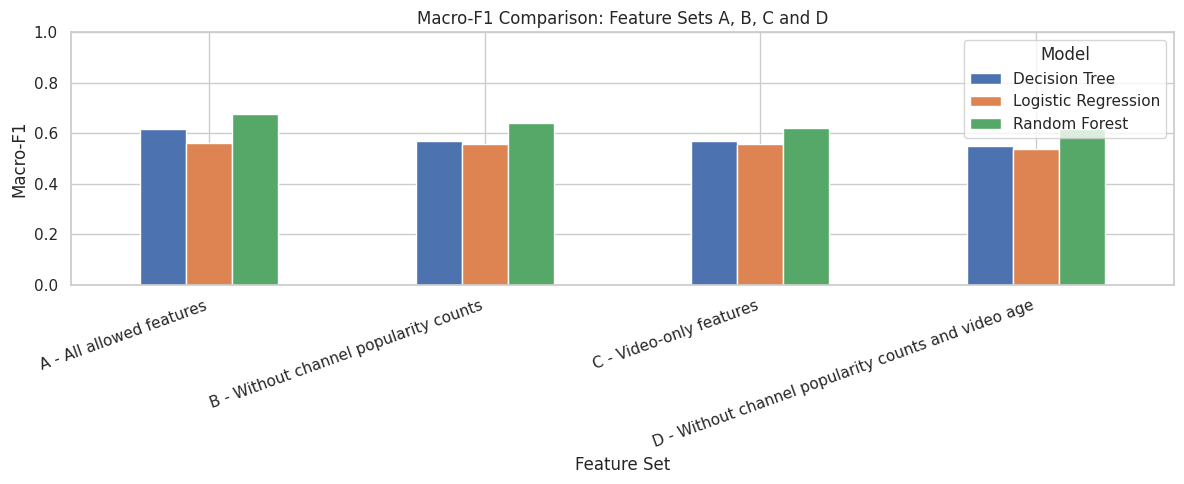

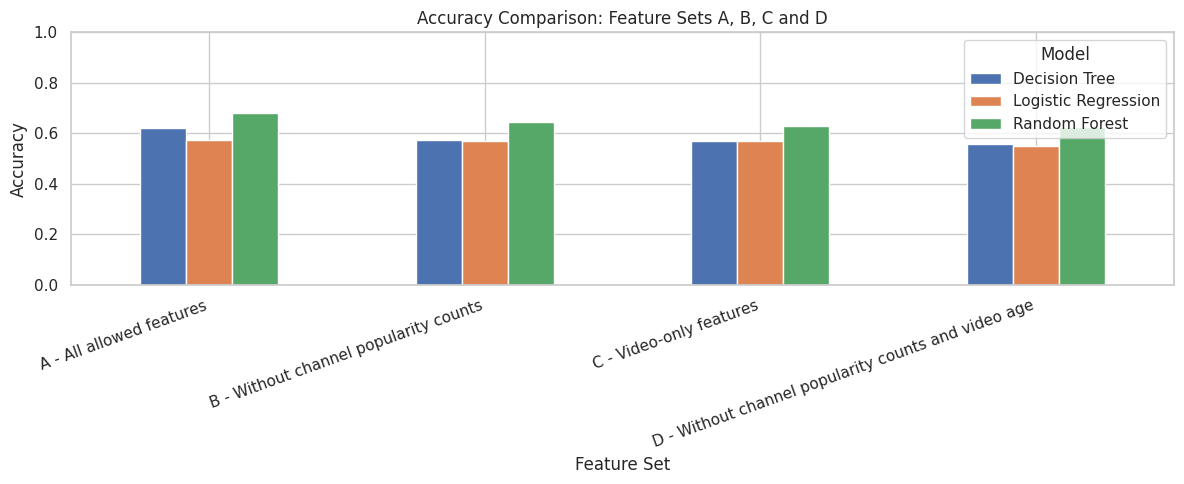

In [ ]:
# Compare every feature-set/model combination.
results_df = pd.DataFrame(results)
display(results_df.round(4))

pivot_f1 = results_df.pivot(index="Feature Set", columns="Model", values="F1 Score")
ax = pivot_f1.plot(kind="bar", figsize=(12, 5))
ax.set_title("Macro-F1 Comparison: Feature Sets A, B, C and D")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

pivot_acc = results_df.pivot(index="Feature Set", columns="Model", values="Accuracy")
ax = pivot_acc.plot(kind="bar", figsize=(12, 5))
ax.set_title("Accuracy Comparison: Feature Sets A, B, C and D")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## Cell 10- Confusion matrices
Each row is the true class; numbers are the share of that class predicted as each label (so the diagonal is the per-class recall). This shows *which classes get confused*.

Best combination: A - All allowed features | Random Forest
Best F1 Score: 0.6775


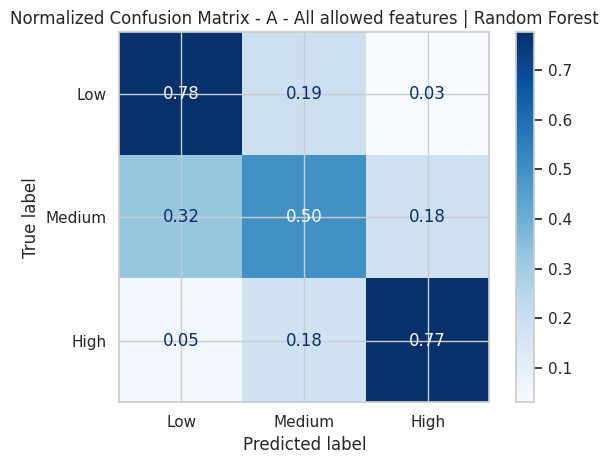

In [ ]:
# Find the true best combination by F1 Score
best_row = results_df.loc[results_df["F1 Score"].idxmax()]
best_key = best_row["Feature Set"] + " | " + best_row["Model"]
print("Best combination:", best_key)
print(f"Best F1 Score: {best_row['F1 Score']:.4f}")

ConfusionMatrixDisplay.from_predictions(
    y_test, predictions[best_key], labels=["Low", "Medium", "High"],
    normalize="true", cmap="Blues", values_format=".2f"
)
plt.title(f"Normalized Confusion Matrix - {best_key}")
plt.tight_layout()
plt.show()

## Cell 11 - Error analysis
For the best model by macro-F1, we check where it makes mistakes. Views are used here **only to analyse errors after prediction** - never as a model input.

In [ ]:
# Error analysis for the best feature-set/model combination by F1 Score.
best_row = results_df.loc[results_df["F1 Score"].idxmax()]
best_key = best_row["Feature Set"] + " | " + best_row["Model"]
y_pred = pd.Series(predictions[best_key], index=y_test.index, name="Predicted")
errors = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
errors = errors.loc[errors["Actual"] != errors["Predicted"]].copy()

# Add context only after prediction; these columns were not model inputs.
context_cols = [c for c in ["V_id", "categoryId", "duration", "months_old", "engagement_rate", "viewCount", "likeCount"] if c in model_df.columns]
errors = errors.join(model_df[context_cols], how="left")
print("Best combination:", best_key)
print("Incorrect Predictions:", len(errors))
display(errors.head(20))
print(classification_report(y_test, y_pred, zero_division=0))

Best combination: A - All allowed features | Random Forest
Incorrect Predictions: 22142


,Actual,Predicted,V_id,categoryId,duration,months_old,engagement_rate,viewCount,likeCount
344117,Medium,Low,_l-o2G99IGk,14,273.0,63,0.598321,11198,67.0
83278,Medium,Low,L8iazJXmGRw,3,136.0,36,0.848552,10842,92.0
74068,Medium,Low,SrlkBl8OlTE,3,204.0,53,0.700560,56098,393.0
170539,Low,Medium,HFX6a8OPtYI,7,333.0,22,0.403199,192957,778.0
156209,Medium,High,9fiSyC2RGwY,6,482.0,44,0.561730,4121906,23154.0
205510,High,Medium,csgrXFCtPqI,8,132.0,36,1.187913,1517030,18021.0
27740,Medium,Low,u-x-mnMCQKE,1,240.0,66,0.656549,21019,138.0
270532,Medium,Low,lkYzTNQ6PjM,11,144.0,38,0.534110,4119,22.0
264713,Medium,Low,Tiyezo1fLRs,10,241.0,81,0.911039,197906,1803.0
224146,Medium,Low,U60obmWODLQ,9,157.0,51,0.533753,405244,2163.0


              precision    recall  f1-score   support

        High       0.79      0.77      0.78     23174
         Low       0.67      0.78      0.72     23175
      Medium       0.57      0.50      0.53     23175

    accuracy                           0.68     69524
   macro avg       0.68      0.68      0.68     69524
weighted avg       0.68      0.68      0.68     69524



In [ ]:
# Export incorrect predictions for review
errors.to_csv("engagement_model_errors.csv", index=True)
results_df = pd.DataFrame(results)
results_df.to_csv("engagement_feature_set_model_comparison.csv", index=False)
print("Saved: engagement_model_errors.csv")
print("Saved: engagement_feature_set_model_comparison.csv")
print("Total errors:", len(errors))
display(errors.head(10))

Saved: engagement_model_errors.csv
Saved: engagement_feature_set_model_comparison.csv
Total errors: 22142


,Actual,Predicted,V_id,categoryId,duration,months_old,engagement_rate,viewCount,likeCount
344117,Medium,Low,_l-o2G99IGk,14,273.0,63,0.598321,11198,67.0
83278,Medium,Low,L8iazJXmGRw,3,136.0,36,0.848552,10842,92.0
74068,Medium,Low,SrlkBl8OlTE,3,204.0,53,0.700560,56098,393.0
170539,Low,Medium,HFX6a8OPtYI,7,333.0,22,0.403199,192957,778.0
156209,Medium,High,9fiSyC2RGwY,6,482.0,44,0.561730,4121906,23154.0
205510,High,Medium,csgrXFCtPqI,8,132.0,36,1.187913,1517030,18021.0
27740,Medium,Low,u-x-mnMCQKE,1,240.0,66,0.656549,21019,138.0
270532,Medium,Low,lkYzTNQ6PjM,11,144.0,38,0.534110,4119,22.0
264713,Medium,Low,Tiyezo1fLRs,10,241.0,81,0.911039,197906,1803.0
224146,Medium,Low,U60obmWODLQ,9,157.0,51,0.533753,405244,2163.0


correct vs incorrect predictions for the best combination

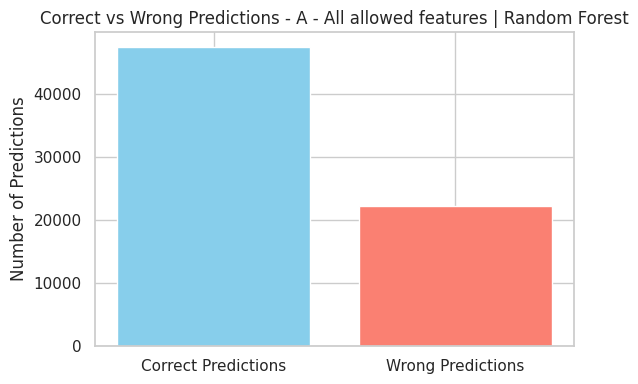

Correct Predictions: 47382
Wrong Predictions: 22142


In [ ]:
# Correct vs incorrect predictions for the best combination.
best_row = results_df.loc[results_df["F1 Score"].idxmax()]
best_key = best_row["Feature Set"] + " | " + best_row["Model"]
y_pred = predictions[best_key]
correct = int((y_test.to_numpy() == y_pred).sum())
incorrect = int((y_test.to_numpy() != y_pred).sum())

plt.figure(figsize=(6, 4))
plt.bar(["Correct Predictions", "Wrong Predictions"], [correct, incorrect], color=["skyblue", "salmon"])
plt.title("Correct vs Wrong Predictions - " + best_key)
plt.ylabel("Number of Predictions")
plt.tight_layout()
plt.show()
print("Correct Predictions:", correct)
print("Wrong Predictions:", incorrect)

In [ ]:
# end